In [1]:
import numpy as np
from itertools import combinations
from functools import lru_cache
from math import comb
from random import Random
from collections import Counter
from sympy import Matrix\

# -1 is an empty space, easier than using squares etc

def det(b, n):
    return int(Matrix(n, n, list(b)).det())

def det2(b, n):
    # just the normal formulas, checking sympy gives the same thing
    if n == 1:
        return b[0]
    if n == 2:
        return b[0]*b[3] - b[1]*b[2]
    if n == 3:
        return (b[0]*(b[4]*b[8]-b[5]*b[7])
                - b[1]*(b[3]*b[8]-b[5]*b[6])
                + b[2]*(b[3]*b[7]-b[4]*b[6]))
    raise ValueError('only works up to 3')

def put(b, i, x):
    assert b[i] == -1
    return b[:i] + (x,) + b[i+1:]

def finals(n, first):
    # get all completed boards with the right number of ones
    m = n*n
    num = (m+1)//2 if first == 1 else m//2
    for places in combinations(range(m), num):
        yield tuple(1 if i in places else 0 for i in range(m))

def show(b, n):
    for i in range(0, n*n, n):
        print(b[i:i+n])

small matrices

In [2]:
print('[A2] 2x2 boards')
counts = Counter()
for b in finals(2, 0):
    d = det(b, 2)
    assert d == det2(b, 2)
    counts[d] += 1
    print(b, 'det =', d)
assert counts == Counter({0:4, 1:1, -1:1})

print('\n[A3/A4] some 3x3 examples')
examples = [
    ((1,1,1, 0,1,0, 0,0,0), 0),
    ((1,1,0, 0,1,0, 0,0,1), 1),
    ((1,0,0, 0,1,1, 0,1,0), -1)
]
for b, expected in examples:
    show(b, 3)
    print('det =', det(b, 3), '\n')
    assert det(b, 3) == det2(b, 3) == expected
assert all(examples[2][0][j] + examples[2][0][3+j] == 1 for j in range(3))

print('[A1] number of singular final boards')
for n in (1,2,3):
    for first in (0,1):
        boards = list(finals(n, first))
        zeros = sum(det(b,n)==0 for b in boards)
        assert all(det(b,n)==det2(b,n) for b in boards)
        print('n =', n, 'starts = P'+str(first), 'singular =', zeros, '/', len(boards))

[A2] 2x2 boards
(1, 1, 0, 0) det = 0
(1, 0, 1, 0) det = 0
(1, 0, 0, 1) det = 1
(0, 1, 1, 0) det = -1
(0, 1, 0, 1) det = 0
(0, 0, 1, 1) det = 0

[A3/A4] some 3x3 examples
(1, 1, 1)
(0, 1, 0)
(0, 0, 0)
det = 0 

(1, 1, 0)
(0, 1, 0)
(0, 0, 1)
det = 1 

(1, 0, 0)
(0, 1, 1)
(0, 1, 0)
det = -1 

[A1] number of singular final boards
n = 1 starts = P0 singular = 1 / 1
n = 1 starts = P1 singular = 0 / 1
n = 2 starts = P0 singular = 4 / 6
n = 2 starts = P1 singular = 4 / 6
n = 3 starts = P0 singular = 90 / 126
n = 3 starts = P1 singular = 54 / 126


find winner

In [3]:
#find winner
def solve(n):
    @lru_cache(None)
    def win(b, turn):
        if -1 not in b:
            return det(b, n) == 0
        options = (win(put(b, i, turn), 1-turn)
                   for i in range(n*n) if b[i] == -1)
        if turn == 0:
            return any(options)
        return all(options)
    return win


def solve_backwards(n, first):
    # do the filled boards first, then go back to the empty one
    if n > 3:
        raise ValueError('too many boards for this version')
    m = n*n
    answers = {}
    for k in range(m, -1, -1):
        ones = (k+1)//2 if first == 1 else k//2
        turn = first if k%2 == 0 else 1-first
        for filled in combinations(range(m), k):
            for one_spots in combinations(filled, ones):
                b = [-1]*m
                for i in filled:
                    b[i] = 0
                for i in one_spots:
                    b[i] = 1
                b = tuple(b)
                if k == m:
                    answers[b] = det2(b, n) == 0
                else:
                    next_boards = [answers[put(b, i, turn)]
                                   for i in range(m) if b[i] == -1]
                    answers[b] = any(next_boards) if turn == 0 else all(next_boards)
    return answers

In [4]:
print('[A1/A7] checking the 2 solvers against each other')
all_results = {}
for n in (1,2,3):
    for first in (0,1):
        f = solve(n)
        other = solve_backwards(n, first)
        for b, val in other.items():
            moves = sum(x!=-1 for x in b)
            turn = first if moves%2==0 else 1-first
            assert f(b, turn) == val
        ans = f((-1,)*(n*n), first)
        assert ans == other[(-1,)*(n*n)]
        all_results[(n, first)] = ans
        print('n', n, 'P'+str(first)+' starts:', 'P0 can win?', ans, 'states:', len(other))

print('\n[A5] P1 starts at top left in 3x3')
f = solve(3)
b = put((-1,)*9, 0, 1)
good = []
bad = []
for i in range(1,9):
    pos = (i//3+1, i%3+1)
    if f(put(b, i, 0), 1):
        good.append(pos)
    else:
        bad.append(pos)
print('winning replies:', good)
print('other replies:', bad)
assert good == [(2,2),(2,3),(3,2),(3,3)]

# checks the other P1 opening positions too
for i in range(9):
    b = put((-1,)*9, i, 1)
    count = sum(f(put(b,j,0),1) for j in range(9) if b[j]==-1)
    assert count == 4
print('P1 can start anywhere and P0 has 4 winning replies, checked')

[A1/A7] checking the 2 solvers against each other
n 1 P0 starts: P0 can win? True states: 2
n 1 P1 starts: P0 can win? False states: 2
n 2 P0 starts: P0 can win? True states: 35
n 2 P1 starts: P0 can win? True states: 35
n 3 P0 starts: P0 can win? True states: 6046
n 3 P1 starts: P0 can win? True states: 6046

[A5] P1 starts at top left in 3x3
winning replies: [(2, 2), (2, 3), (3, 2), (3, 3)]
other replies: [(1, 2), (1, 3), (2, 1), (3, 1)]
P1 can start anywhere and P0 has 4 winning replies, checked


check 2x2

In [5]:
x = 0
y = 0
for i in range(4):
    # P0 starts. complete same row or same column
    b = put((-1,)*4, i, 0)
    r, c = divmod(i, 2)
    row_spot = 2*r + (1-c)
    col_spot = 2*(1-r) + c
    for j in range(4):
        if b[j] == -1:
            bb = put(b, j, 1)
            k = row_spot if bb[row_spot] == -1 else col_spot
            bb = put(bb, k, 0)
            bb = put(bb, bb.index(-1), 1)
            assert det(bb, 2) == 0
            x += 1

    # P1 starts. P0 uses other diagonal square
    b = put((-1,)*4, i, 1)
    b = put(b, 3-i, 0)
    for j in range(4):
        if b[j] == -1:
            bb = put(b, j, 1)
            bb = put(bb, bb.index(-1), 0)
            assert det(bb, 2) == 0
            y += 1
assert (x,y) == (12,8)
print('[A10] P0 starting:', x, 'cases worked')
print('[A10] P1 starting:', y, 'cases worked')

[A10] P0 starting: 12 cases worked
[A10] P1 starting: 8 cases worked


symmetry to reduce cases

In [6]:
def change(b, n, kind):
    rows = [list(b[i*n:(i+1)*n]) for i in range(n)]
    if kind == 'rows':
        rows[0], rows[-1] = rows[-1], rows[0]
    if kind == 'cols':
        for row in rows:
            row[0], row[-1] = row[-1], row[0]
    if kind == 'transpose':
        rows = [[rows[j][i] for j in range(n)] for i in range(n)]
    return tuple(x for row in rows for x in row)

for n in (2,3):
    for first in (0,1):
        results = solve_backwards(n, first)
        checks = 0
        for b, val in results.items():
            for kind in ('rows', 'cols', 'transpose'):
                assert results[change(b,n,kind)] == val
                checks += 1
        print('[A11] n',n,'P'+str(first),'starts, checked',checks,'symmetries')

[A11] n 2 P0 starts, checked 105 symmetries
[A11] n 2 P1 starts, checked 105 symmetries
[A11] n 3 P0 starts, checked 18138 symmetries
[A11] n 3 P1 starts, checked 18138 symmetries


reachjable states 

In [7]:
def states(n):
    m = n*n
    return sum(comb(m,k)*comb(k,k//2) for k in range(m+1))

for n, num in ((1,2),(2,35),(3,6046),(4,10165779)):
    assert states(n) == num
    print('[A6] S',n,'=',format(states(n),','))
print('n=4 number from formula, havent enumerated them all')

[A6] S 1 = 2
[A6] S 2 = 35
[A6] S 3 = 6,046
[A6] S 4 = 10,165,779
n=4 number from formula, havent enumerated them all


P1 ableto block?

In [8]:
def states(n):
    m = n*n
    return sum(comb(m,k)*comb(k,k//2) for k in range(m+1))

for n, num in ((1,2),(2,35),(3,6046),(4,10165779)):
    assert states(n) == num
    print('[A6] S',n,'=',format(states(n),','))
print('n=4 number from formula, havent enumerated them all')

[A6] S 1 = 2
[A6] S 2 = 35
[A6] S 3 = 6,046
[A6] S 4 = 10,165,779
n=4 number from formula, havent enumerated them all


p1 ablocks 0 rows

In [9]:
def block(b, n):
    for r in range(n):
        row = b[r*n:(r+1)*n]
        if 0 in row and 1 not in row:
            for i in range(r*n, (r+1)*n):
                if b[i] == -1:
                    return i
            raise AssertionError('zero row already done')
    return b.index(-1)

def zero_row(b, n):
    return any(all(x == 0 for x in b[r*n:(r+1)*n]) for r in range(n))

for n in (2,3):
    for first in (0,1):
        seen = set()
        ends = set()
        def explore(b, turn):
            if (b,turn) in seen:
                return
            seen.add((b,turn))
            if -1 not in b:
                assert not zero_row(b,n)
                ends.add(b)
            elif turn == 0:
                for i in range(n*n):
                    if b[i] == -1:
                        explore(put(b,i,0), 1)
            else:
                i = block(b,n)
                bb = put(b,i,1)
                assert all(0 not in bb[r*n:(r+1)*n] or 1 in bb[r*n:(r+1)*n] for r in range(n))
                explore(bb,0)
        explore((-1,)*(n*n), first)
        print('[A8] n',n,'P'+str(first),'starts. tried',len(seen),'states and',len(ends),'end boards, no zero rows')

[A8] n 2 P0 starts. tried 21 states and 4 end boards, no zero rows
[A8] n 2 P1 starts. tried 10 states and 2 end boards, no zero rows
[A8] n 3 P0 starts. tried 512 states and 24 end boards, no zero rows
[A8] n 3 P1 starts. tried 269 states and 28 end boards, no zero rows


larger board exerperiment

In [10]:
def pairs_for(n):
    pairs = [(j,n+j) for j in range(n)] + [(2*n+j,3*n+j) for j in range(n)]
    rest = list(range(4*n,n*n))
    spare = rest.pop() if len(rest)%2 else None
    pairs += list(zip(rest[::2], rest[1::2]))
    assert len(pairs)*2 + (spare is not None) == n*n
    return pairs, spare

def my_move(b, first, pairs, spare):
    if first == 0 and spare is not None and all(x==-1 for x in b):
        return spare
    # if there is a 1 with empty partner, put zero there
    for a,c in pairs:
        if b[a] == 1 and b[c] == -1:
            return c
        if b[c] == 1 and b[a] == -1:
            return a
    # otherwise just start a new pair
    for a,c in pairs:
        if b[a] == b[c] == -1:
            return a
    raise AssertionError('no move found')

def pair_ok(b, pairs):
    half = 0
    for a,c in pairs:
        if b[a] == b[c] == -1:
            pass
        elif {b[a],b[c]} == {0,1}:
            pass
        elif (b[a],b[c]) in ((-1,0),(0,-1)):
            half += 1
        else:
            return False
    return half <= 1

def their_move(b, pairs, spare, style, rng):
    free = [i for i,x in enumerate(b) if x==-1]
    if style == 'first':
        return free[0]
    if style == 'last':
        return free[-1]
    if style == 'spare early' and spare in free:
        return spare
    if style == 'spare late' and spare in free and len(free)>1:
        return next(i for i in free if i!=spare)
    if style == 'finish pairs':
        for a,c in pairs:
            if b[a] == 0 and c in free:
                return c
            if b[c] == 0 and a in free:
                return a
    if style == 'new pairs':
        for a,c in pairs:
            if a in free and c in free:
                return a
    return rng.choice(free)

styles = ['first', 'last', 'spare early', 'spare late', 'finish pairs', 'new pairs', 'random']
for n in (4,5):
    pairs, spare = pairs_for(n)
    for first in (0,1):
        rng = Random(20261124 + 100*n + first)
        games = 0
        for style in styles:
            for trial in range(8):
                b = (-1,)*(n*n)
                turn = first
                while -1 in b:
                    if turn == 0:
                        i = my_move(b,first,pairs,spare)
                        b = put(b,i,0)
                        assert pair_ok(b,pairs)
                    else:
                        i = their_move(b,pairs,spare,style,rng)
                        b = put(b,i,1)
                    turn = 1-turn
                assert all(b[j]+b[n+j] == 1 for j in range(n))
                assert all(b[2*n+j]+b[3*n+j] == 1 for j in range(n))
                assert det(b,n) == 0
                games += 1
        print('[A9] n',n,'P'+str(first),'starts:',games,'games all worked (not exhaustive)')

[A9] n 4 P0 starts: 56 games all worked (not exhaustive)
[A9] n 4 P1 starts: 56 games all worked (not exhaustive)
[A9] n 5 P0 starts: 56 games all worked (not exhaustive)
[A9] n 5 P1 starts: 56 games all worked (not exhaustive)


3x3 winning state counts

In [11]:

# checking how many boards P0 can still win from
# after each move on a 3x3 grid

for first in (0, 1):
    results = solve_backwards(3, first)

    print('\n3x3, P' + str(first) + ' starts')
    print('moves | boards | P0 can win')

    for k in range(10):
        boards = []

        for b, win in results.items():
            if sum(x != -1 for x in b) == k:
                boards.append(win)

        print(k, '|', len(boards), '|', sum(boards))

    assert results[(-1,) * 9] == True



3x3, P0 starts
moves | boards | P0 can win
0 | 1 | 1
1 | 9 | 9
2 | 72 | 72
3 | 252 | 252
4 | 756 | 756
5 | 1260 | 756
6 | 1680 | 1416
7 | 1260 | 666
8 | 630 | 450
9 | 126 | 90

3x3, P1 starts
moves | boards | P0 can win
0 | 1 | 1
1 | 9 | 9
2 | 72 | 36
3 | 252 | 198
4 | 756 | 198
5 | 1260 | 810
6 | 1680 | 624
7 | 1260 | 846
8 | 630 | 270
9 | 126 | 54


In [12]:

# trying more row pairs to see how low the rank gets

def more_pairs(n):
    pairs = []

    for r in range(0, n-1, 2):
        for c in range(n):
            pairs.append((r*n+c, (r+1)*n+c))

    rest = list(range(2*(n//2)*n, n*n))
    spare = rest.pop() if len(rest)%2 else None
    pairs += list(zip(rest[::2], rest[1::2]))

    return pairs, spare


for n in range(4, 9):
    pairs, spare = more_pairs(n)
    bound = n - (n//2 - 1)

    biggest = 0
    games = 0

    for first in (0, 1):
        rng = Random(90 + n*10 + first)

        styles = ['first', 'last', 'spare early',
                  'spare late', 'finish pairs',
                  'new pairs', 'random']

        for style in styles:
            for trial in range(3):
                b = (-1,) * (n*n)
                turn = first

                while -1 in b:
                    if turn == 0:
                        i = my_move(b, first, pairs, spare)
                        b = put(b, i, 0)
                        assert pair_ok(b, pairs)
                    else:
                        i = their_move(b, pairs, spare, style, rng)
                        b = put(b, i, 1)

                    turn = 1-turn

                # each 2 rows should add up to all ones
                for r in range(0, 2*(n//2), 2):
                    assert all(
                        b[r*n+c] + b[(r+1)*n+c] == 1
                        for c in range(n)
                    )

                rank = Matrix(n, n, list(b)).rank()
                assert rank <= bound
                assert det(b, n) == 0

                biggest = max(biggest, rank)
                games += 1

    print('n', n, ': rank <=', bound,
          '| biggest seen', biggest,
          '| tried', games, 'games')


n 4 : rank <= 3 | biggest seen 3 | tried 42 games
n 5 : rank <= 4 | biggest seen 4 | tried 42 games
n 6 : rank <= 4 | biggest seen 4 | tried 42 games
n 7 : rank <= 5 | biggest seen 5 | tried 42 games
n 8 : rank <= 5 | biggest seen 5 | tried 42 games


dichromatic graph


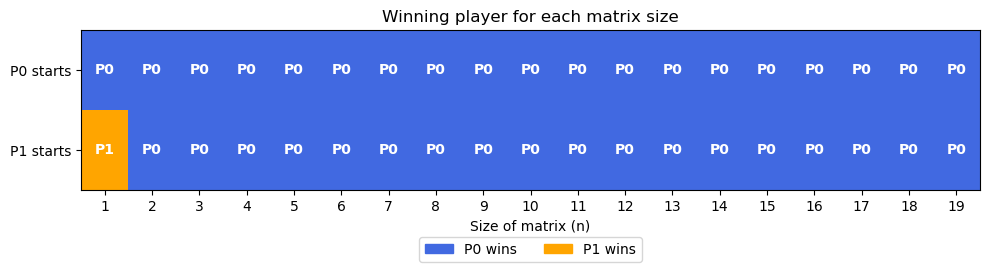

In [13]:

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib.patches import Rectangle
# 0 means P0 wins, 1 means P1 wins
# using the results we proved, not brute force

ns = list(range(1, 20))
winners = []

for first in (0, 1):
    row = []

    for n in ns:
        if n == 1:
            winner = first
        else:
            winner = 0

        row.append(winner)

    winners.append(row)

# make the graph
colours = ListedColormap(['royalblue', 'orange'])

plt.figure(figsize=(10, 3))
plt.imshow(winners, cmap=colours, vmin=0, vmax=1,
           aspect='auto')

plt.xticks(range(19), ns)
plt.yticks([0, 1], ['P0 starts', 'P1 starts'])
plt.xlabel('Size of matrix (n)')
plt.title('Winning player for each matrix size')

# write the winner in each box
for i in range(2):
    for j in range(19):
        plt.text(j, i, 'P' + str(winners[i][j]),
                 ha='center', va='center',
                 color='white', fontweight='bold')

plt.legend(handles=[
    Patch(color='royalblue', label='P0 wins'),
    Patch(color='orange', label='P1 wins')
], loc='upper center', bbox_to_anchor=(0.5, -0.25),
   ncol=2)

plt.tight_layout()
plt.show()


overwrites

In [14]:

# what if P1 can change one 0 into a 1 at the end?

def safe_after_change(b, n, formula=False):
    get_det = det2 if formula else det

    if get_det(b, n) != 0:
        return False

    for i in range(n*n):
        if b[i] == 0:
            bb = b[:i] + (1,) + b[i+1:]
            if get_det(bb, n) != 0:
                return False

    return True


def overwrite_solver(n):
    @lru_cache(None)
    def win(b, turn):
        if -1 not in b:
            return safe_after_change(b, n)

        opts = (win(put(b, i, turn), 1-turn)
                for i in range(n*n) if b[i] == -1)

        return any(opts) if turn == 0 else all(opts)

    return win


# second way of checking it
def overwrite_backwards(n, first):
    m = n*n
    ans = {}

    for k in range(m, -1, -1):
        ones = (k+1)//2 if first == 1 else k//2
        turn = first if k%2 == 0 else 1-first

        for filled in combinations(range(m), k):
            for one_cells in combinations(filled, ones):
                b = [-1]*m

                for i in filled:
                    b[i] = 0
                for i in one_cells:
                    b[i] = 1

                b = tuple(b)

                if k == m:
                    ans[b] = safe_after_change(b, n, formula=True)
                else:
                    opts = [ans[put(b, i, turn)]
                            for i in range(m) if b[i] == -1]
                    ans[b] = any(opts) if turn == 0 else all(opts)

    return ans


for n in (1, 2, 3):
    for first in (0, 1):
        f = overwrite_solver(n)
        other = overwrite_backwards(n, first)

        # check the two ways agree on every board
        for b, result in other.items():
            k = sum(x != -1 for x in b)
            turn = first if k%2 == 0 else 1-first
            assert f(b, turn) == result

        good = sum(safe_after_change(b, n)
                   for b in finals(n, first))
        total = sum(1 for b in finals(n, first))

        print('n', n, 'P'+str(first)+' starts:',
              'P0 can win?', f((-1,)*(n*n), first),
              '| safe end boards:', good, '/', total)

print('all checks worked')


n 1 P0 starts: P0 can win? False | safe end boards: 0 / 1
n 1 P1 starts: P0 can win? False | safe end boards: 0 / 1
n 2 P0 starts: P0 can win? False | safe end boards: 0 / 6
n 2 P1 starts: P0 can win? False | safe end boards: 0 / 6
n 3 P0 starts: P0 can win? False | safe end boards: 9 / 126
n 3 P1 starts: P0 can win? False | safe end boards: 9 / 126
all checks worked


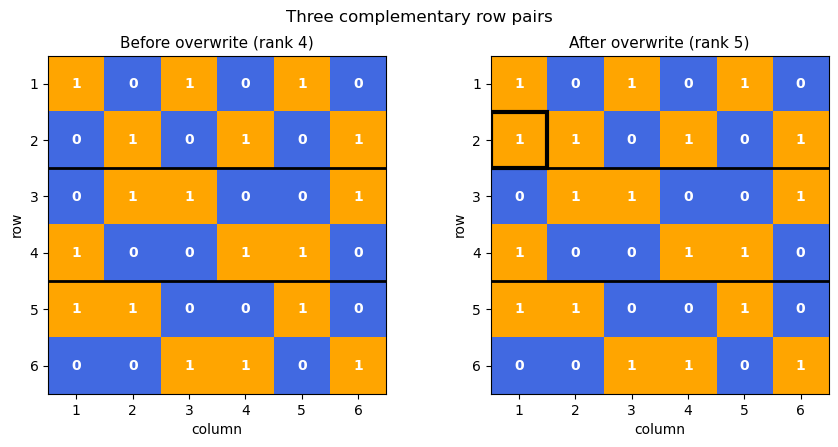

In [15]:
# example 6x6 board with 3 matching row pairs
b = [
    [1,0,1,0,1,0],
    [0,1,0,1,0,1],
    [0,1,1,0,0,1],
    [1,0,0,1,1,0],
    [1,1,0,0,1,0],
    [0,0,1,1,0,1]
]

changed = [row[:] for row in b]
changed[1][0] = 1   # P1 changes this zero

assert Matrix(b).rank() == 4
assert Matrix(changed).rank() == 5
assert Matrix(b).det() == Matrix(changed).det() == 0

colours = ListedColormap(['royalblue', 'orange'])

fig, axs = plt.subplots(1, 2, figsize=(9, 4.4))

for ax, data, title in zip(
    axs,
    [b, changed],
    ['Before overwrite (rank 4)', 'After overwrite (rank 5)']
):
    ax.imshow(data, cmap=colours, vmin=0, vmax=1)

    ax.set_xticks(range(6))
    ax.set_yticks(range(6))
    ax.set_xticklabels(range(1, 7))
    ax.set_yticklabels(range(1, 7))

    ax.set_xlabel('column')
    ax.set_ylabel('row')
    ax.set_title(title, fontsize=11)

    for i in range(6):
        for j in range(6):
            ax.text(j, i, data[i][j],
                    ha='center', va='center',
                    color='white', fontweight='bold')

    # separate the 3 pairs of rows
    for cut in (1.5, 3.5):
        ax.axhline(cut, color='black', linewidth=2)

# mark which cell was changed
axs[1].add_patch(
    Rectangle((-.5, .5), 1, 1,
              fill=False, edgecolor='black',
              linewidth=3)
)

plt.suptitle('Three complementary row pairs')
plt.tight_layout()
plt.savefig('overwrite_example.png', dpi=220,
            bbox_inches='tight')
plt.show()
